In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine

# 1. Loading the Datasets

# 1.1 Load dataset
wine = load_wine()

# 1.2 Create the data frames
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

print("1. DATASET OVERVIEW: Wine Classification")
print(f"Dataset Shape: {X.shape[0]} samples, {X.shape[1]} features\n")

print("First 5 Rows")
display(X.head())

print("\nFeature Names")
print(X.columns.tolist())

print("\nTarget Labels & Class Mapping")
for label, name in zip(range(len(wine.target_names)), wine.target_names):
    print(f"Class {label}: {name}")

print("\nClass Distribution")
print(y.value_counts().sort_index())

1. DATASET OVERVIEW: Wine Classification
Dataset Shape: 178 samples, 13 features

First 5 Rows


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Feature Names
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target Labels & Class Mapping
Class 0: class_0
Class 1: class_1
Class 2: class_2

Class Distribution
target
0    59
1    71
2    48
Name: count, dtype: int64


The Wine Classification dataset contains 178 samples and 13 numerical features derived from chemical analyses of wines grown in the same region in Italy. The multi-class target labels are mapped directly to original scikit-learn target names: Class 0 (class_0, 59 samples), Class 1 (class_1, 71 samples), and Class 2 (class_2, 48 samples). All original class labels (0, 1, and 2) are preserved without modification.

In [2]:

# 2. Dataset Quality Checks

# 2.1 Missing values and duplicates
missing_per_column = X.isnull().sum()
total_missing = missing_per_column.sum()
duplicates = X.duplicated().sum()

print("2. DATASET QUALITY CHECKS")
print("Missing Values per Column")
print(missing_per_column)
print(f"\nTotal Missing Values Across Dataset: {total_missing}")
if total_missing == 0:
    print("Explicit Status: No missing values are present in any feature column.")

print(f"\nDuplicate Rows: {duplicates}")
if duplicates == 0:
    print("Explicit Status: No duplicate rows present in the dataset.")

# 2.2 Potential outliers (IQR method)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers_iqr = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

print("\nOutlier Detection (IQR Method)")
print("Number of potential outliers detected per feature:")
print(outliers_iqr[outliers_iqr > 0].sort_values(ascending=False))

# 2.3 Data types
print("\nData Types per Feature")
print(X.dtypes)

num_cols = X.select_dtypes(include=[np.number]).shape[1]
cat_cols = X.select_dtypes(exclude=[np.number]).shape[1]
print(f"\nTotal Numerical Features: {num_cols}")
print(f"Total Categorical Features: {cat_cols}")

2. DATASET QUALITY CHECKS
Missing Values per Column
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total Missing Values Across Dataset: 0
Explicit Status: No missing values are present in any feature column.

Duplicate Rows: 0
Explicit Status: No duplicate rows present in the dataset.

Outlier Detection (IQR Method)
Number of potential outliers detected per feature:
alcalinity_of_ash    4
color_intensity      4
magnesium            4
ash                  3
malic_acid           3
proanthocyanins      2
hue                  1
dtype: int64

Data Types per Feature
alcohol                 

Quality verification confirms that there are zero missing values across all 13 feature columns and zero duplicate rows in the dataset. All 13 features are continuous numerical variables (float64), with zero categorical features present.

IQR based outlier detection identifies isolated potential outliers in features such as ash, alcalinity_of_ash, magnesium, proanthocyanins, color_intensity, and hue. Unusually high or low feature values can significantly expand the distance metrics in distance-based algorithms like KNN, giving outlying observations an unearned influence over nearest-neighbor queries. Conversely, tree-based models like Decision Trees remain invariant to monotonic feature transformations and outlier magnitude. Because these values represent genuine chemical variations across wine cultivars rather than measurement artifacts, no observations are deleted or clipped.  

=== 3.1 Descriptive Statistics ===


,mean,median,min,max,std,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000
total_phenols,2.295112,2.355,0.98,3.88,0.625851,1.7425,2.8000
flavanoids,2.029270,2.135,0.34,5.08,0.998859,1.2050,2.8750
nonflavanoid_phenols,0.361854,0.340,0.13,0.66,0.124453,0.2700,0.4375
proanthocyanins,1.590899,1.555,0.41,3.58,0.572359,1.2500,1.9500
color_intensity,5.058090,4.690,1.28,13.00,2.318286,3.2200,6.2000



=== 3.2 Class Distribution and Feature Correlations ===


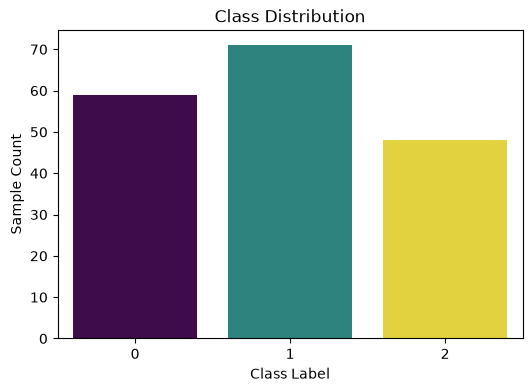

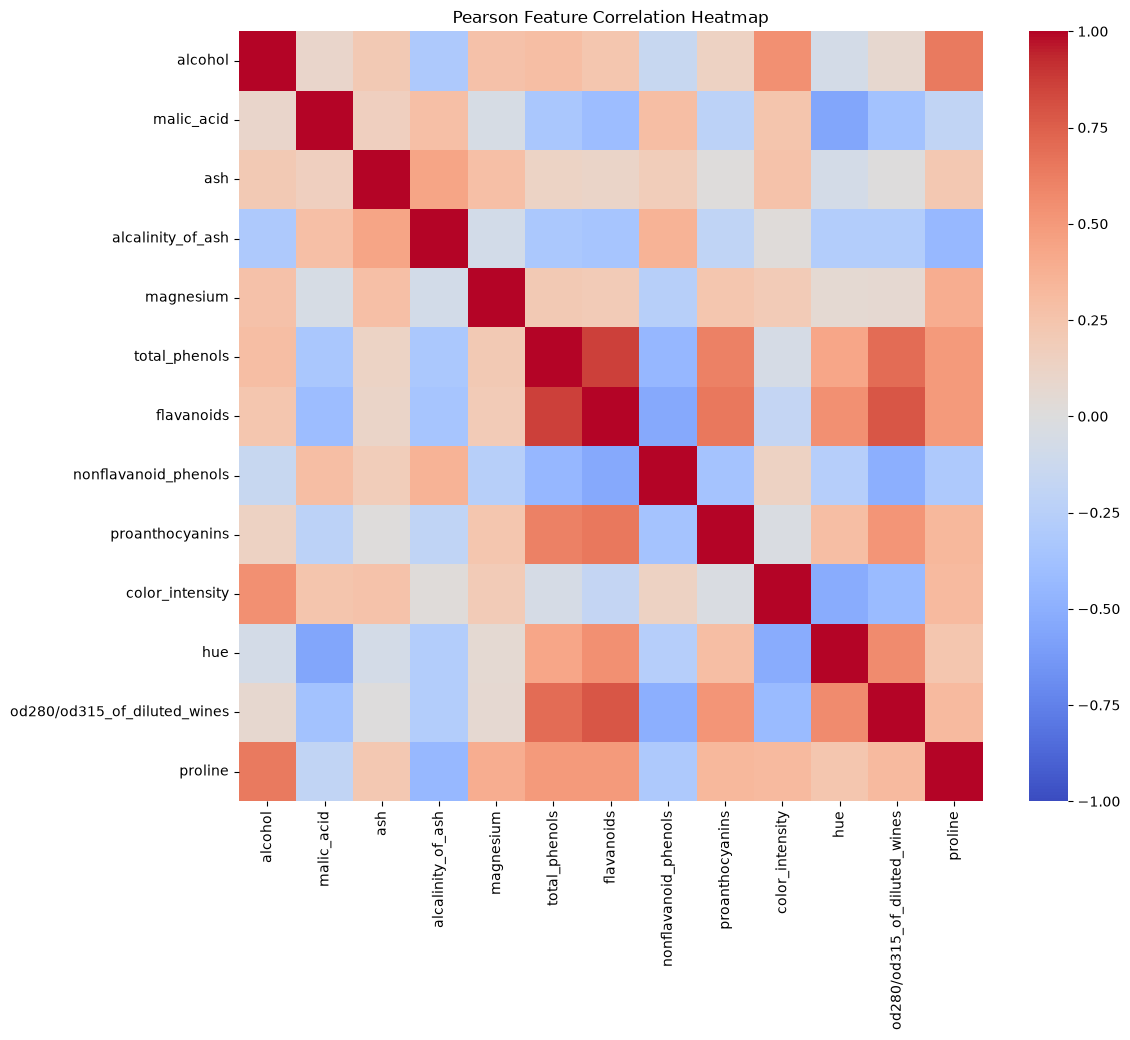

Top 3 unique feature pairs by absolute correlation:
total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

=== 3.3 Feature Boxplots ===


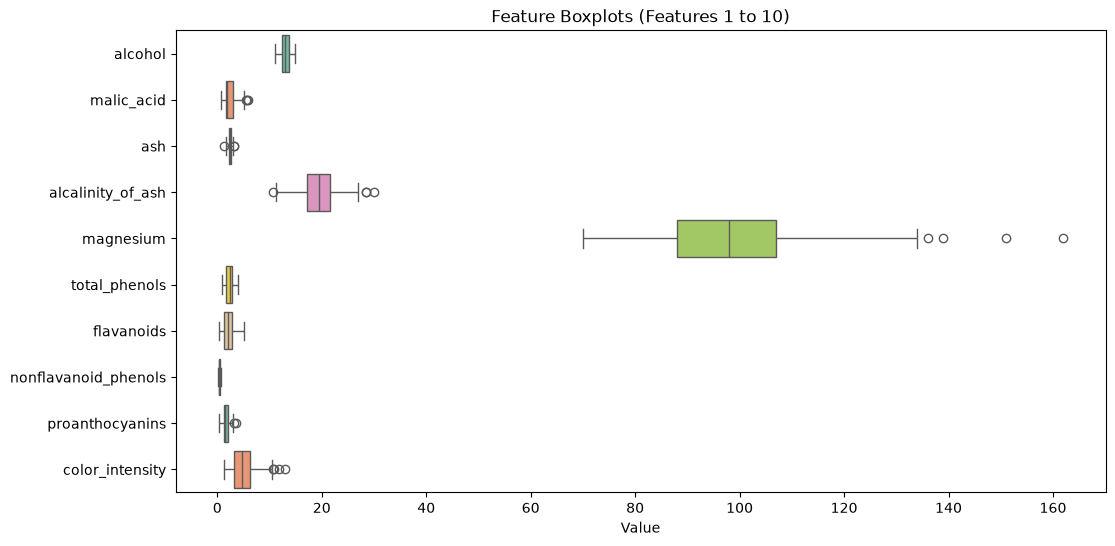

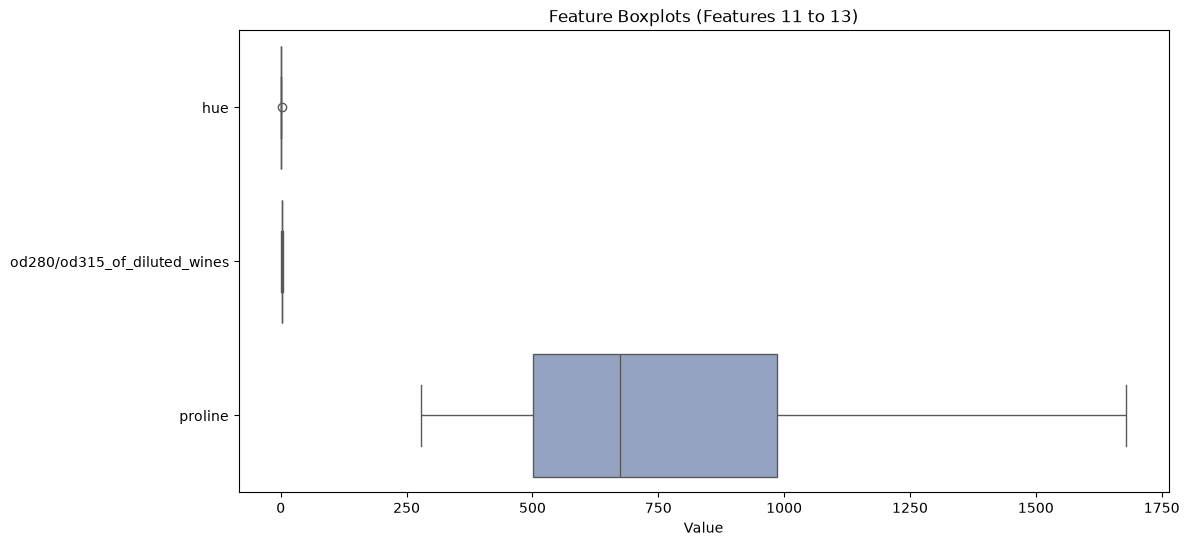

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 3. Exploratory Data Analysis (EDA)
# ==========================================

print("=== 3.1 Descriptive Statistics ===")
# Generate descriptive stats: mean, median (50%), min, max, std, Q1 (25%), Q3 (75%)
desc_stats = X.describe().T[['mean', '50%', 'min', 'max', 'std', '25%', '75%']]
desc_stats = desc_stats.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'})
display(desc_stats)

# ==========================================
# 3.2 Class Distribution & Correlations
# ==========================================
print("\n=== 3.2 Class Distribution and Feature Correlations ===")

# Plot Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y, hue=y, palette="viridis", legend=False)
plt.title("Class Distribution")
plt.savefig("figures/wine_class_distribution.png", dpi=150, bbox_inches="tight")
plt.xlabel("Class Label")
plt.ylabel("Sample Count")
plt.show()

# Plot Pearson Feature-Correlation Heatmap
plt.figure(figsize=(12, 10))
corr_matrix = X.corr(method='pearson')
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Pearson Feature Correlation Heatmap")
plt.savefig("figures/wine_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Extract top 3 unique feature pairs by absolute correlation
upper_triangle = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
corr_pairs = corr_matrix.where(upper_triangle).abs().stack().sort_values(ascending=False)
top_3_pairs = corr_pairs.head(3)

print("Top 3 unique feature pairs by absolute correlation:")
print(top_3_pairs)

# ==========================================
# 3.3 Boxplots
# ==========================================
print("\n=== 3.3 Feature Boxplots ===")
# Group features into subsets so boxplots remain readable
features = X.columns
features_per_plot = 10 
num_plots = (len(features) + features_per_plot - 1) // features_per_plot

for i in range(num_plots):
    start_idx = i * features_per_plot
    end_idx = min((i + 1) * features_per_plot, len(features))
    subset_cols = features[start_idx:end_idx]
    
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=X[subset_cols], orient="h", palette="Set2")
    plt.title(f"Feature Boxplots (Features {start_idx+1} to {end_idx})")
    plt.savefig(f"figures/wine_boxplots_{i+1}.png", dpi=150, bbox_inches="tight")
    plt.xlabel("Value")
    plt.show()

### Section 3 interpretation

The Wine features have notably different units and ranges, particularly proline and color intensity compared with the phenolic measurements. The strongest correlation pairs indicate related chemical measurements, while the boxplots identify a small number of potential extreme values. These observations are descriptive only: no rows or features are removed, and preprocessing is fitted only on training subsets in later sections.

Sections 4-10 use the fixed stratified test set, three training/validation seeds, training-only StandardScaler preprocessing, the required classifier grid, and K-Means. Results and figures are exported for the combined project inventory.


4-10. WINE

4.2 Split summary, class counts and original indices
dataset  seed     subset  n_samples  percentage_of_dataset          class_counts                                                                                                                                                                                                                                                                                                                                                                                                                                                        indices
   wine    42      train        124              69.662921 {0: 41, 1: 50, 2: 33} [163, 148, 116, 122, 115, 147, 46, 141, 57, 168, 36, 159, 103, 29, 23, 68, 101, 50, 11, 113, 114, 34, 27, 125, 165, 49, 74, 83, 162, 31, 30, 25, 44, 149, 26, 9, 63, 13, 77, 24, 142, 85, 144, 109, 41, 71, 78, 16, 92, 47, 90, 96, 150, 69, 133, 138, 91, 124, 15, 126, 139, 140, 95, 82, 56, 40, 12, 161, 99, 61, 136, 170, 156, 3,

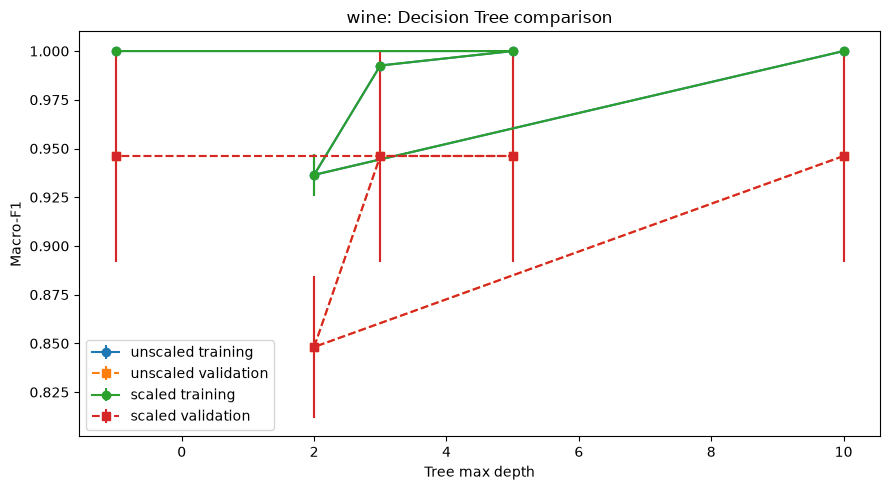

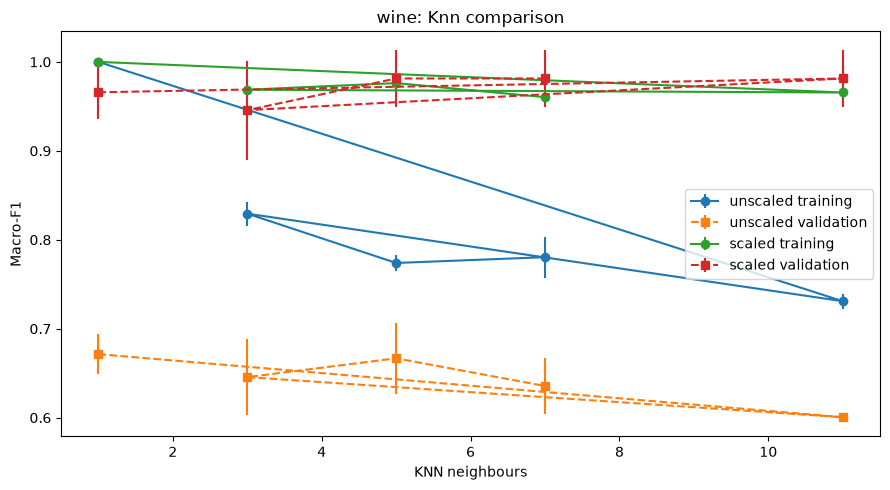


7-9. Classifier results
Classifier runs: 66
Selected configuration:
                                            0
dataset                                  wine
selected_configuration_id  wine_knn_scaled_11
selected_algorithm                        knn
selected_representation                scaled
selected_parameter             n_neighbors=11
evaluation_seed                            42
validation_f1_mean                   0.981352
validation_f1_std                    0.032299
test_accuracy                             1.0
test_precision_macro                      1.0
test_recall_macro                         1.0
test_f1_macro                             1.0
test_roc_auc                              1.0
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg   

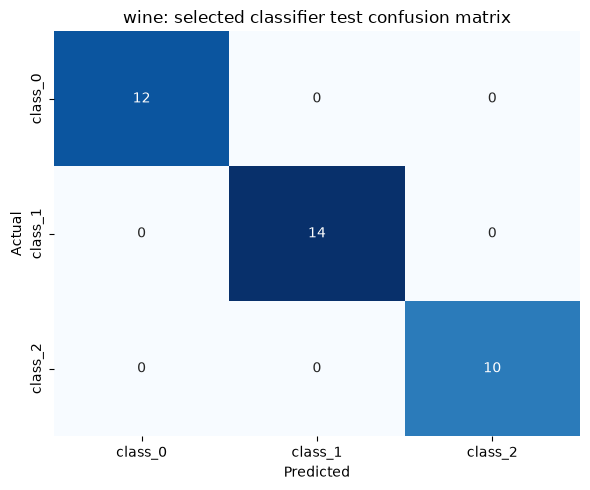

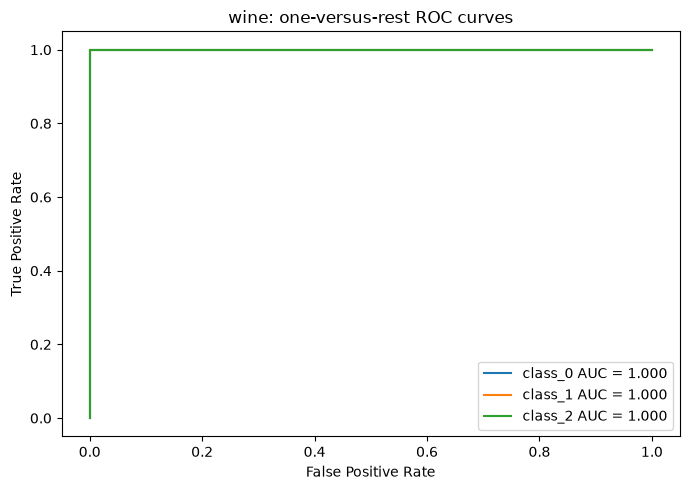

Manual class_0 metrics: 1.0 1.0 1.0

unscaled test class/cluster contingency table:
cluster     0   1  2
true_class          
0           2  10  0
1           5   0  9
2           7   0  3


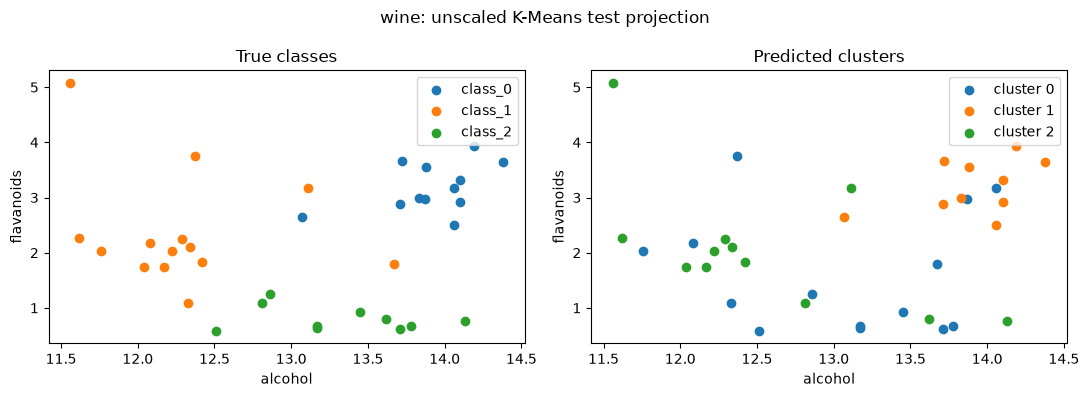


scaled test class/cluster contingency table:
cluster      0   1   2
true_class            
0           12   0   0
1            1  13   0
2            0   0  10


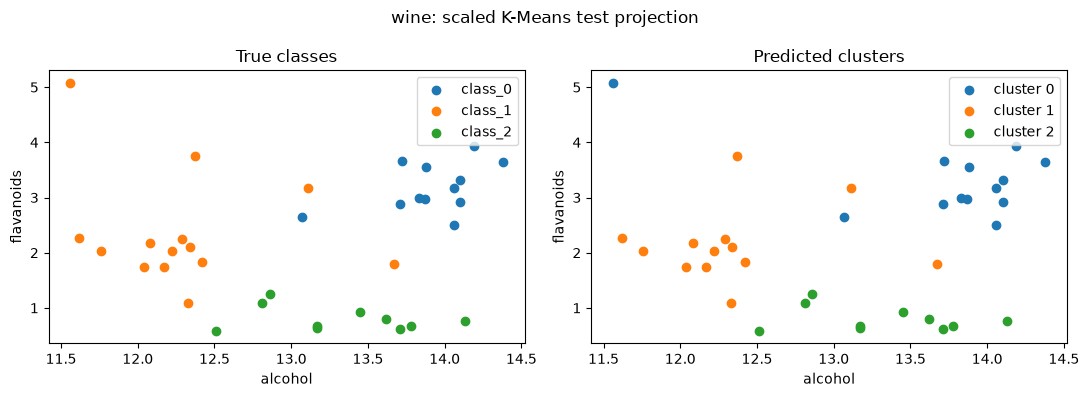


Saved CSV outputs for wine.


In [4]:
from midterm_pipeline import run_dataset

wine_results = run_dataset(
    dataset_name="wine",
    X=X,
    y=y,
    target_names=wine.target_names,
    n_clusters=3,
    plot_features=["alcohol", "flavanoids"],
)

## 4. Splitting the Datasets

Each repetition uses the same fixed 36-row test set and approximately 70/10/20 training, validation and test proportions. The seed changes only the training/validation membership.

## 5. Data Preprocessing and Scaling

No imputation was needed because the quality checks found no missing values. StandardScaler was fitted separately on each training subset, and the original indexed features were retained in both representations.

## 6. Preparing the Two Data Representations

Both representations retain all original features and the same sample indices.

## 7. Training the Classification Models

All 66 required classifier fits were recorded. Scaling is most important for KNN because Euclidean distances are affected by feature units; tree results are unchanged because tree thresholds are not distance-based.

## 8. Measuring Validation Performance

Configurations were selected using mean validation macro-F1, followed by the specified tie-break rules; test scores were not used for selection.

## 9. Evaluating the Selected Model

The selected seed-42 scaled KNN uses eleven neighbours and reaches 1.000 for accuracy, macro-F1 and ROC-AUC on the fixed test set. This is a result for one predeclared test split, not proof of perfect generalisation. The one-versus-rest ROC curves describe how changing a threshold trades false positives against false negatives.

## 10. K-Means Clustering

Scaling improves the Wine test ARI from 0.373 to 0.909. The contingency table shows much stronger class/cluster alignment after scaling, while cluster IDs remain unsupervised labels and are not compared as classification predictions.

## 11. Comparing the Two Datasets

The comparison below is generated from the exported run tables rather than from test performance alone. Validation means and standard deviations describe the three repeated training/validation splits; the fixed seed-42 test results are reported separately.

In [5]:
classifier_summary_all = pd.read_csv("classifier_summary.csv")
classifier_test_all = pd.read_csv("classifier_test.csv")
kmeans_test_all = pd.read_csv("kmeans_test.csv")

print("11. COMPARING THE TWO DATASETS")
print("Best validation configurations:")
for dataset_name in ["breast_cancer", "wine"]:
    rows = classifier_summary_all[classifier_summary_all["dataset"] == dataset_name]
    best = rows.sort_values(
        ["val_f1_macro_mean", "val_accuracy_mean", "val_f1_macro_std", "configuration_id"],
        ascending=[False, False, True, True],
    ).iloc[0]
    print(dataset_name, best[["algorithm", "representation", "parameter", "val_f1_macro_mean", "val_f1_macro_std"]].to_dict())

print("\nFinal classifier results:")
display(classifier_test_all)
print("\nFinal K-Means results:")
display(kmeans_test_all)
print("\nConclusions:")
print("1. Both datasets selected scaled KNN, but the selected neighbour counts differ: 7 for Breast Cancer and 11 for Wine.")
print("2. Scaling affects KNN most: the best mean validation macro-F1 rises from 0.916 to 0.968 for Breast Cancer and from 0.671 to 0.981 for Wine.")
print("3. Deeper trees do not always improve performance: Breast Cancer reaches a plateau at depth 10, while Wine improves sharply after depth 2 and then plateaus. Seed standard deviations show that validation subsets are small and variable.")
print("4. Breast Cancer has malignant false negatives in the selected classifier; Wine has no errors on this fixed test sample, which does not prove perfect generalisation.")
print("5. Scaled K-Means agrees more closely with the labels for both datasets, with test ARI 0.735 for Breast Cancer and 0.909 for Wine. A future investigation would assess additional predeclared validation splits or a different distance-based method, without retuning on the test set.")

11. COMPARING THE TWO DATASETS
Best validation configurations:
breast_cancer {'algorithm': 'knn', 'representation': 'scaled', 'parameter': 'n_neighbors=7', 'val_f1_macro_mean': 0.9676749826749828, 'val_f1_macro_std': 0.029718024557980914}
wine {'algorithm': 'knn', 'representation': 'scaled', 'parameter': 'n_neighbors=11', 'val_f1_macro_mean': 0.9813519813519814, 'val_f1_macro_std': 0.032299315758860164}

Final classifier results:


,dataset,selected_algorithm,selected_representation,selected_parameter,evaluation_seed,validation_f1_mean,validation_f1_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc,selected_configuration_id
0,breast_cancer,knn,scaled,n_neighbors=7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757,breast_cancer_knn_scaled_7
1,wine,knn,scaled,n_neighbors=11,42,0.981352,0.032299,1.000000,1.00,1.000000,1.000000,1.000000,wine_knn_scaled_11



Final K-Means results:


,dataset,representation,seed,n_clusters,test_cluster_counts,test_ari,test_silhouette
0,breast_cancer,unscaled,42,2,"{0: np.int64(86), 1: np.int64(28)}",0.558488,0.711999
1,breast_cancer,scaled,42,2,"{0: np.int64(74), 1: np.int64(40)}",0.735381,0.325062
2,wine,unscaled,42,3,"{0: np.int64(14), 1: np.int64(10), 2: np.int64...",0.373323,0.492880
3,wine,scaled,42,3,"{0: np.int64(13), 1: np.int64(13), 2: np.int64...",0.908794,0.271120



Conclusions:
1. Both datasets selected scaled KNN, but the selected neighbour counts differ: 7 for Breast Cancer and 11 for Wine.
2. Scaling affects KNN most: the best mean validation macro-F1 rises from 0.916 to 0.968 for Breast Cancer and from 0.671 to 0.981 for Wine.
3. Deeper trees do not always improve performance: Breast Cancer reaches a plateau at depth 10, while Wine improves sharply after depth 2 and then plateaus. Seed standard deviations show that validation subsets are small and variable.
4. Breast Cancer has malignant false negatives in the selected classifier; Wine has no errors on this fixed test sample, which does not prove perfect generalisation.
5. Scaled K-Means agrees more closely with the labels for both datasets, with test ARI 0.735 for Breast Cancer and 0.909 for Wine. A future investigation would assess additional predeclared validation splits or a different distance-based method, without retuning on the test set.


## 12. Required Run and Output Inventory

The project exports the six required CSV files: 132 classifier runs, 44 classifier-summary rows, 2 classifier-test rows, 12 K-Means runs, 4 K-Means-summary rows and 4 K-Means-test rows. The `figures/` directory contains the required EDA, classifier and clustering figures. The raw run tables remain in CSV format so they can be inspected without copying all rows into the report.